In [5]:
import numpy as np
import pandas as pd
df=pd.read_csv("work_from_home_burnout_dataset.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

#--------------------------------------------------

# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check dataset size
print("\nDataset Shape:")
print(df.shape)

# 5. Get summary statistics
print("\nSummary Statistics:")
print(df.describe(include="all"))

#-------------------------------------------------------

# 1. Count each burnout risk category
print("Burnout Risk Distribution:")
print(df["burnout_risk"].value_counts())

# 2. Calculate average burnout score
print("\nAverage Burnout Score:")
print(df["burnout_score"].mean())

# 3. Calculate median burnout score
print("\nMedian Burnout Score:")
print(df["burnout_score"].median())

#-----------------------------------------------------

# Compare work and sleep habits by burnout risk

print("Burnout Risk vs Work and Sleep Hours:")

result = df.groupby("burnout_risk")[
    ["work_hours", "screen_time_hours", "sleep_hours", "burnout_score"]
].mean()

print(result.round(2))


First 5 rows:
   user_id day_type  work_hours  screen_time_hours  meetings_count  \
0        1  Weekday        9.59              11.86               4   
1        1  Weekend        7.38              10.33               4   
2        1  Weekend        6.31               8.92               1   
3        1  Weekday        8.34              10.70               4   
4        1  Weekend        6.97               9.83               1   

   breaks_taken  after_hours_work  sleep_hours  task_completion_rate  \
0             2                 0         7.55                  91.2   
1             1                 0         6.69                  82.0   
2             2                 0         8.87                  80.6   
3             1                 1         8.13                  70.0   
4             2                 0         5.85                  67.1   

   burnout_score burnout_risk  
0          19.17          Low  
1          29.70          Low  
2          32.93          Low  
3   

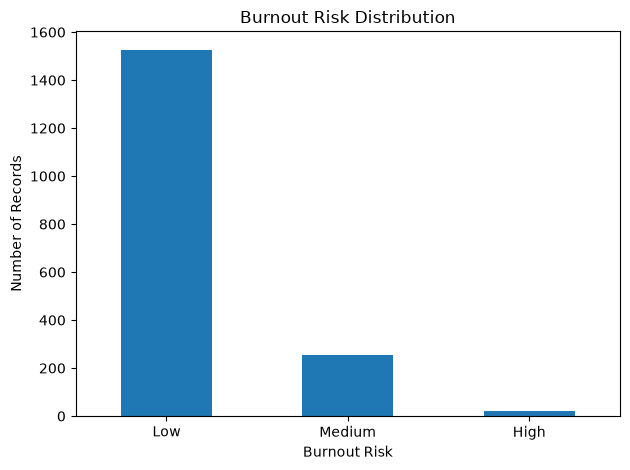

In [6]:
#Data Visualization

import matplotlib.pyplot as plt

# Count burnout risk categories
risk_counts = df["burnout_risk"].value_counts()

# Create bar chart
risk_counts.plot(kind="bar")

plt.title("Burnout Risk Distribution")
plt.xlabel("Burnout Risk")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Correlation with Burnout Score:
burnout_score           1.000000
screen_time_hours       0.122636
work_hours              0.119319
meetings_count          0.084996
after_hours_work        0.017967
breaks_taken            0.003992
sleep_hours            -0.006151
user_id                -0.061085
task_completion_rate   -0.960015
Name: burnout_score, dtype: float64


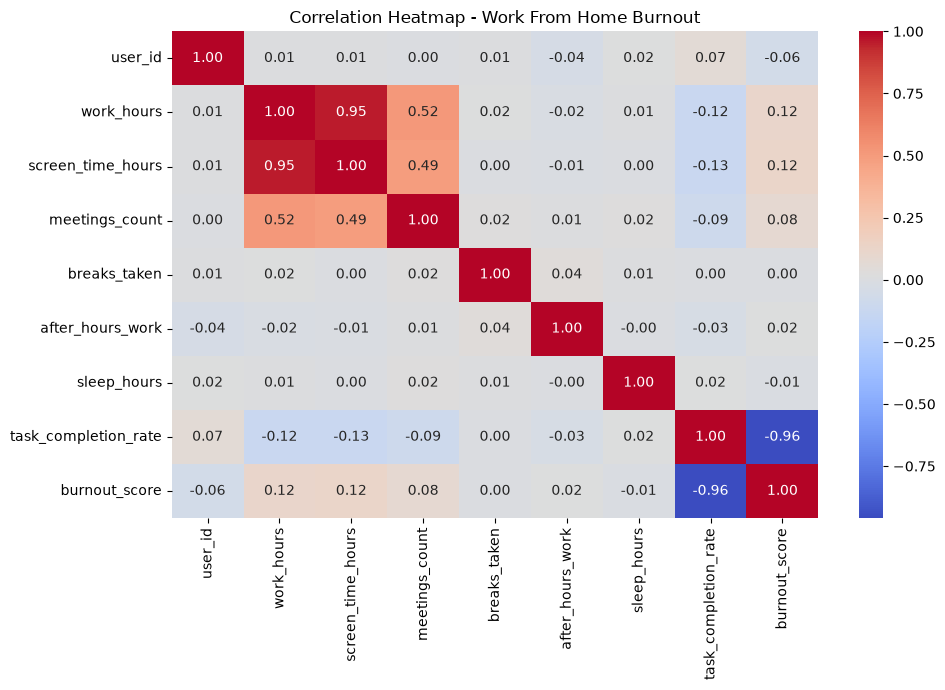

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numerical_df.corr()

print("Correlation with Burnout Score:")
print(correlation["burnout_score"].sort_values(ascending=False))

# Plot correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap - Work From Home Burnout")
plt.tight_layout()
plt.show()


In [8]:

# Select input features
X = df[
    [
        "day_type",
        "work_hours",
        "screen_time_hours",
        "meetings_count",
        "breaks_taken",
        "after_hours_work",
        "sleep_hours",
        "task_completion_rate"
    ]
]

# Select target column
y = df["burnout_risk"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)


Features (X):
  day_type  work_hours  screen_time_hours  meetings_count  breaks_taken  \
0  Weekday        9.59              11.86               4             2   
1  Weekend        7.38              10.33               4             1   
2  Weekend        6.31               8.92               1             2   
3  Weekday        8.34              10.70               4             1   
4  Weekend        6.97               9.83               1             2   

   after_hours_work  sleep_hours  task_completion_rate  
0                 0         7.55                  91.2  
1                 0         6.69                  82.0  
2                 0         8.87                  80.6  
3                 1         8.13                  70.0  
4                 0         5.85                  67.1  

Target (y):
0    Low
1    Low
2    Low
3    Low
4    Low
Name: burnout_risk, dtype: str

X Shape: (1800, 8)
y Shape: (1800,)


In [9]:
# Convert categorical column into numerical columns
X = pd.get_dummies(
    X,
    columns=["day_type"],
    dtype=int
)

print("Encoded Features:")
print(X.head())

print("\nColumn Names:")
print(X.columns.tolist())

print("\nShape:", X.shape)


Encoded Features:
   work_hours  screen_time_hours  meetings_count  breaks_taken  \
0        9.59              11.86               4             2   
1        7.38              10.33               4             1   
2        6.31               8.92               1             2   
3        8.34              10.70               4             1   
4        6.97               9.83               1             2   

   after_hours_work  sleep_hours  task_completion_rate  day_type_Weekday  \
0                 0         7.55                  91.2                 1   
1                 0         6.69                  82.0                 0   
2                 0         8.87                  80.6                 0   
3                 1         8.13                  70.0                 1   
4                 0         5.85                  67.1                 0   

   day_type_Weekend  
0                 0  
1                 1  
2                 1  
3                 0  
4                 

In [10]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (1440, 9)
X_test shape: (360, 9)
y_train shape: (1440,)
y_test shape: (360,)


In [12]:

from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

# Predict burnout risk for test data
y_pred = model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).tolist())

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])



Model training completed!
First 10 Actual Values:
['Low', 'Low', 'Low', 'Low', 'Low', 'Low', 'Low', 'Low', 'Medium', 'High']

First 10 Predicted Values:
['Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Medium' 'Medium']


In [13]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# 2. Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 3. Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"]))



Model Accuracy: 93.06 %

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         4
         Low       0.98      0.96      0.97       305
      Medium       0.72      0.84      0.77        51

    accuracy                           0.93       360
   macro avg       0.57      0.60      0.58       360
weighted avg       0.93      0.93      0.93       360


Confusion Matrix:
[[292  13   0]
 [  6  43   2]
 [  0   4   0]]


In [14]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Give more importance to High burnout risk
model_v2 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        "Low": 1,
        "Medium": 2,
        "High": 10
    }
)

# Train using training data only
model_v2.fit(X_train, y_train)

# Predict test data
y_pred_v2 = model_v2.predict(X_test)

print("New Model Accuracy:",
      round(accuracy_score(y_test, y_pred_v2) * 100, 2), "%")

print("\nUpdated Classification Report:")
print(classification_report(
    y_test,
    y_pred_v2,
    labels=["Low", "Medium", "High"],
    zero_division=0
))


New Model Accuracy: 94.44 %

Updated Classification Report:
              precision    recall  f1-score   support

         Low       0.98      0.97      0.98       305
      Medium       0.78      0.84      0.81        51
        High       0.00      0.00      0.00         4

    accuracy                           0.94       360
   macro avg       0.59      0.61      0.60       360
weighted avg       0.94      0.94      0.94       360



In [15]:
# compare two models


from sklearn.metrics import accuracy_score, classification_report

# Model 1 predictions
pred1 = model.predict(X_test)

# Model 2 predictions
pred2 = model_v2.predict(X_test)

print("MODEL 1 - Balanced Weights")
print("Accuracy:", round(accuracy_score(y_test, pred1) * 100, 2), "%")
print(classification_report(
    y_test, pred1,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("\nMODEL 2 - Higher High-Risk Weight")
print("Accuracy:", round(accuracy_score(y_test, pred2) * 100, 2), "%")
print(classification_report(
    y_test, pred2,
    labels=["Low", "Medium", "High"],
    zero_division=0
))


MODEL 1 - Balanced Weights
Accuracy: 93.06 %
              precision    recall  f1-score   support

         Low       0.98      0.96      0.97       305
      Medium       0.72      0.84      0.77        51
        High       0.00      0.00      0.00         4

    accuracy                           0.93       360
   macro avg       0.57      0.60      0.58       360
weighted avg       0.93      0.93      0.93       360


MODEL 2 - Higher High-Risk Weight
Accuracy: 94.44 %
              precision    recall  f1-score   support

         Low       0.98      0.97      0.98       305
      Medium       0.78      0.84      0.81        51
        High       0.00      0.00      0.00         4

    accuracy                           0.94       360
   macro avg       0.59      0.61      0.60       360
weighted avg       0.94      0.94      0.94       360



Feature Importance:
                Feature  Importance
6  task_completion_rate    0.712052
0            work_hours    0.073067
5           sleep_hours    0.071425
1     screen_time_hours    0.071345
3          breaks_taken    0.030238
2        meetings_count    0.024448
4      after_hours_work    0.008364
7      day_type_Weekday    0.004673
8      day_type_Weekend    0.004388


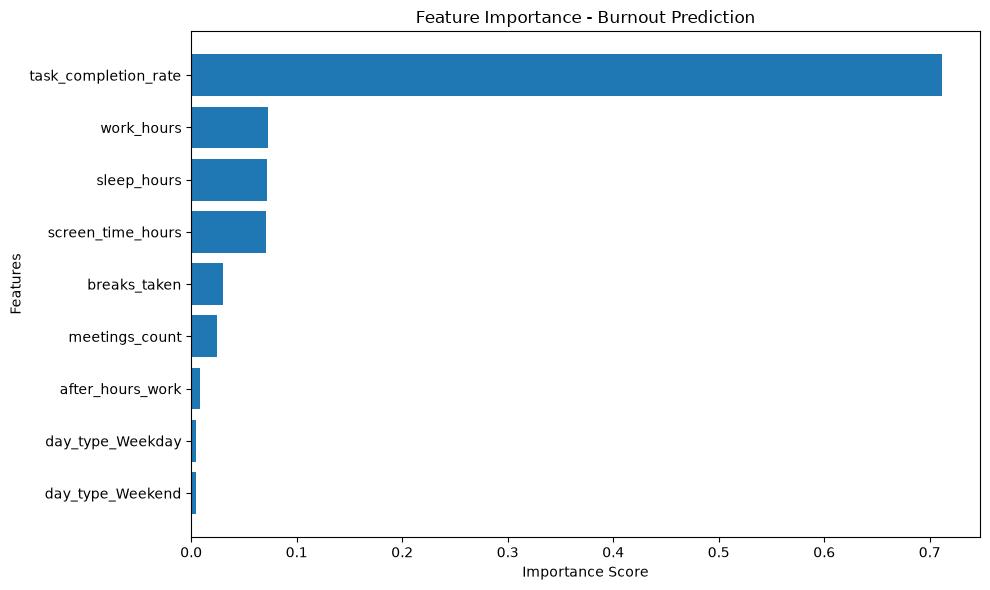

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_v2.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
print(importance_df)

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance - Burnout Prediction")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [17]:

import joblib

# Save the trained model
joblib.dump(model_v2, "burnout_model.pkl")

# Save the feature column names
joblib.dump(X_train.columns.tolist(), "burnout_features.pkl")

print("Model saved successfully!")
print("Feature names saved successfully!")


Model saved successfully!
Feature names saved successfully!


In [18]:

# Load the saved model
loaded_model = joblib.load("burnout_model.pkl")

# Load the saved feature names
loaded_features = joblib.load("burnout_features.pkl")

print("Model loaded successfully!")
print("Features:", loaded_features)


Model loaded successfully!
Features: ['work_hours', 'screen_time_hours', 'meetings_count', 'breaks_taken', 'after_hours_work', 'sleep_hours', 'task_completion_rate', 'day_type_Weekday', 'day_type_Weekend']


In [19]:

import pandas as pd
import joblib

# Load saved model and feature names
loaded_model = joblib.load("burnout_model.pkl")
loaded_features = joblib.load("burnout_features.pkl")

# Get user input
day_type = input("Enter day type (Weekday/Weekend): ")
work_hours = float(input("Enter work hours: "))
screen_time_hours = float(input("Enter screen time hours: "))
meetings_count = int(input("Enter meetings count: "))
breaks_taken = int(input("Enter breaks taken: "))
after_hours_work = int(input("After-hours work? (0=No, 1=Yes): "))
sleep_hours = float(input("Enter sleep hours: "))
task_completion_rate = float(input("Enter task completion rate: "))

# Create input DataFrame
user_data = pd.DataFrame([{
    "day_type": day_type,
    "work_hours": work_hours,
    "screen_time_hours": screen_time_hours,
    "meetings_count": meetings_count,
    "breaks_taken": breaks_taken,
    "after_hours_work": after_hours_work,
    "sleep_hours": sleep_hours,
    "task_completion_rate": task_completion_rate
}])

# Convert day_type into numerical columns
user_data = pd.get_dummies(
    user_data,
    columns=["day_type"],
    dtype=int
)

# Add any missing training columns and arrange their order
user_data = user_data.reindex(
    columns=loaded_features,
    fill_value=0
)

# Predict burnout risk
prediction = loaded_model.predict(user_data)

print("\nPredicted Burnout Risk:", prediction[0])



Predicted Burnout Risk: Low


In [ ]:
#Evaluation code
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Predict test data
y_pred = model_v2.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
))


Model Accuracy: 94.44 %

Classification Report:
              precision    recall  f1-score   support

         Low       0.98      0.97      0.98       305
      Medium       0.78      0.84      0.81        51
        High       0.00      0.00      0.00         4

    accuracy                           0.94       360
   macro avg       0.59      0.61      0.60       360
weighted avg       0.94      0.94      0.94       360


Confusion Matrix:
[[297   8   0]
 [  6  43   2]
 [  0   4   0]]


In [21]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

# Create Model v3
model_v3 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        "Low": 1,
        "Medium": 2,
        "High": 20
    }
)

# Train the model
model_v3.fit(X_train, y_train)

# Predict test data
y_pred_v3 = model_v3.predict(X_test)

# Evaluate model
print(
    "Model v3 Accuracy:",
    round(accuracy_score(y_test, y_pred_v3) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_v3,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_v3,
    labels=["Low", "Medium", "High"]
))



Model v3 Accuracy: 94.72 %

Classification Report:
              precision    recall  f1-score   support

         Low       0.98      0.98      0.98       305
      Medium       0.80      0.84      0.82        51
        High       0.00      0.00      0.00         4

    accuracy                           0.95       360
   macro avg       0.59      0.61      0.60       360
weighted avg       0.94      0.95      0.95       360


Confusion Matrix:
[[298   7   0]
 [  6  43   2]
 [  0   4   0]]


In [22]:

import pandas as pd

# Actual and predicted values comparison
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_v3
})

# Show actual High-risk records
high_results = comparison[
    comparison["Actual"] == "High"
]

print("Actual High-risk records:")
print(high_results)

print("\nPrediction counts:")
print(y_pred_v3.tolist().count("High"))
print("records predicted as High")


Actual High-risk records:
     Actual Predicted
1137   High    Medium
1279   High    Medium
328    High    Medium
327    High    Medium

Prediction counts:
2
records predicted as High


In [23]:

print("Burnout Risk counts:")
print(df["burnout_risk"].value_counts())

print("\nBurnout Score by Risk:")
print(
    df.groupby("burnout_risk")["burnout_score"]
      .agg(["count", "min", "median", "max", "mean"])
      .round(2)
)


Burnout Risk counts:
burnout_risk
Low       1527
Medium     253
High        20
Name: count, dtype: int64

Burnout Score by Risk:
              count     min  median     max    mean
burnout_risk                                       
High             20  110.22  121.38  143.92  122.57
Low            1527    2.50   34.72   69.92   36.34
Medium          253   70.01   82.19  109.99   84.09


In [24]:

# Correlation between numerical features and burnout score

numeric_columns = [
    "work_hours",
    "screen_time_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate",
    "burnout_score"
]

correlation = df[numeric_columns].corr()

print(
    correlation["burnout_score"]
    .sort_values(ascending=False)
    .round(3)
)


burnout_score           1.000
screen_time_hours       0.123
work_hours              0.119
meetings_count          0.085
after_hours_work        0.018
breaks_taken            0.004
sleep_hours            -0.006
task_completion_rate   -0.960
Name: burnout_score, dtype: float64


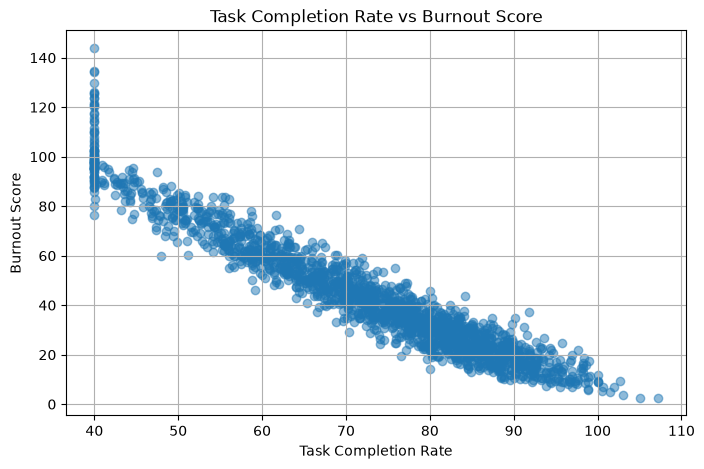

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["task_completion_rate"],
    df["burnout_score"],
    alpha=0.5
)

plt.xlabel("Task Completion Rate")
plt.ylabel("Burnout Score")
plt.title("Task Completion Rate vs Burnout Score")

plt.grid(True)
plt.show()


In [27]:

print(
    df[["task_completion_rate", "burnout_score"]]
    .corr()
    .round(3)
)

print(df.groupby("burnout_risk")["task_completion_rate"].agg(
    ["min", "max", "mean"]
).round(2))


                      task_completion_rate  burnout_score
task_completion_rate                  1.00          -0.96
burnout_score                        -0.96           1.00
               min    max   mean
burnout_risk                    
High          40.0   40.0  40.00
Low           47.9  107.2  76.86
Medium        40.0   64.4  47.42


In [28]:

high_data = df[df["burnout_risk"] == "High"]

print("High-risk records:")
print(
    high_data[
        [
            "work_hours",
            "screen_time_hours",
            "meetings_count",
            "breaks_taken",
            "after_hours_work",
            "sleep_hours",
            "task_completion_rate",
            "burnout_score",
            "burnout_risk"
        ]
    ].head(10)
)


High-risk records:
     work_hours  screen_time_hours  meetings_count  breaks_taken  \
148        9.05              11.45               2             3   
149        5.69               9.32               0             5   
316       10.29              11.92               3             4   
317        6.54               9.35               5             5   
318       10.15              14.03               4             2   
319        8.31              11.32               4             4   
327        9.97              12.38               2             1   
328        8.91              11.08               1             2   
329        7.35               9.78               7             5   
939        8.42              10.81               4             3   

     after_hours_work  sleep_hours  task_completion_rate  burnout_score  \
148                 1         7.09                  40.0         117.35   
149                 1         8.65                  40.0         120.70   
316    

In [29]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Remove task_completion_rate from features
X_without_task = X.drop(
    columns=["task_completion_rate"]
)

# Split data using the same random seed
from sklearn.model_selection import train_test_split

X_train_ab, X_test_ab, y_train_ab, y_test_ab = train_test_split(
    X_without_task,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train a new model
model_ab = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        "Low": 1,
        "Medium": 2,
        "High": 20
    }
)

model_ab.fit(X_train_ab, y_train_ab)

# Predict and evaluate
y_pred_ab = model_ab.predict(X_test_ab)

print(
    "Accuracy without task_completion_rate:",
    round(accuracy_score(y_test_ab, y_pred_ab) * 100, 2),
    "%"
)

print(classification_report(
    y_test_ab,
    y_pred_ab,
    labels=["Low", "Medium", "High"],
    zero_division=0
))


Accuracy without task_completion_rate: 83.61 %
              precision    recall  f1-score   support

         Low       0.85      0.98      0.91       305
      Medium       0.25      0.04      0.07        51
        High       0.00      0.00      0.00         4

    accuracy                           0.84       360
   macro avg       0.37      0.34      0.33       360
weighted avg       0.76      0.84      0.78       360



In [30]:

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
burnout_risk
Low       1222
Medium     202
High        16
Name: count, dtype: int64

Testing target distribution:
burnout_risk
Low       305
Medium     51
High        4
Name: count, dtype: int64


In [31]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

model_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        "Low": 1,
        "Medium": 2,
        "High": 20
    }
)

# Evaluate accuracy across 4 folds
scores = cross_val_score(
    model_cv,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy for each fold:")
print(scores.round(3))

print("\nMean CV Accuracy:")
print(round(scores.mean() * 100, 2), "%")


Accuracy for each fold:
[0.956 0.956 0.94  0.953]

Mean CV Accuracy:
95.11 %


In [32]:

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

model_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        "Low": 1,
        "Medium": 2,
        "High": 20
    }
)

recall_scores = cross_val_score(
    model_cv,
    X,
    y,
    cv=cv,
    scoring="recall_macro"
)

print("Macro Recall for each fold:")
print(recall_scores.round(3))

print("\nMean Macro Recall:")
print(round(recall_scores.mean(), 3))


Macro Recall for each fold:
[0.631 0.618 0.656 0.614]

Mean Macro Recall:
0.63


In [33]:

from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier

model_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight={
        "Low": 1,
        "Medium": 2,
        "High": 20
    }
)

results = cross_validate(
    model_cv,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "high_recall": "recall_macro"
    }
)

print("Accuracy per fold:")
print(results["test_accuracy"].round(3))

print("\nMacro Recall per fold:")
print(results["test_high_recall"].round(3))


Accuracy per fold:
[0.956 0.956 0.94  0.953]

Macro Recall per fold:
[0.631 0.618 0.656 0.614]


In [35]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

y_cv_pred = cross_val_predict(
    model_cv,
    X,
    y,
    cv=cv
)

print("Classification Report:")
print(classification_report(
    y,
    y_cv_pred,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y,
    y_cv_pred,
    labels=["Low", "Medium", "High"]
))

Classification Report:
              precision    recall  f1-score   support

         Low       0.98      0.98      0.98      1527
      Medium       0.80      0.86      0.83       253
        High       0.11      0.05      0.07        20

    accuracy                           0.95      1800
   macro avg       0.63      0.63      0.63      1800
weighted avg       0.95      0.95      0.95      1800


Confusion Matrix:
[[1493   34    0]
 [  27  218    8]
 [   0   19    1]]


In [36]:

from imblearn.over_sampling import RandomOverSampler
from collections import Counter

# Check original training data
print("Before Oversampling:")
print(Counter(y_train))

# Create oversampler
ros = RandomOverSampler(random_state=42)

# Balance training data only
X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train, y_train
)

# Check balanced data
print("\nAfter Oversampling:")
print(Counter(y_train_resampled))

print("\nOriginal Training Shape:", X_train.shape)
print("Resampled Training Shape:", X_train_resampled.shape)


Before Oversampling:
Counter({'Low': 1222, 'Medium': 202, 'High': 16})

After Oversampling:
Counter({'Low': 1222, 'Medium': 1222, 'High': 1222})

Original Training Shape: (1440, 9)
Resampled Training Shape: (3666, 9)


In [37]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Create a new model
model_v4 = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train using balanced training data
model_v4.fit(X_train_resampled, y_train_resampled)

# Predict on original test data
y_pred_v4 = model_v4.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred_v4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_v4,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_v4,
    labels=["Low", "Medium", "High"]
))


Accuracy: 0.9388888888888889

Classification Report:
              precision    recall  f1-score   support

         Low       0.98      0.97      0.97       305
      Medium       0.76      0.82      0.79        51
        High       0.00      0.00      0.00         4

    accuracy                           0.94       360
   macro avg       0.58      0.60      0.59       360
weighted avg       0.94      0.94      0.94       360


Confusion Matrix:
[[296   9   0]
 [  7  42   2]
 [  0   4   0]]


In [38]:

print("Burnout Score by Risk:")
print(
    df.groupby("burnout_risk")["burnout_score"]
      .agg(["min", "max", "mean"])
)

print("\nTask Completion Rate by Risk:")
print(
    df.groupby("burnout_risk")["task_completion_rate"]
      .agg(["min", "max", "mean"])
)

print("\nCorrelation:")
print(
    df[["burnout_score", "task_completion_rate"]]
      .corr()
)


Burnout Score by Risk:
                 min     max        mean
burnout_risk                            
High          110.22  143.92  122.571000
Low             2.50   69.92   36.340747
Medium         70.01  109.99   84.087826

Task Completion Rate by Risk:
               min    max       mean
burnout_risk                        
High          40.0   40.0  40.000000
Low           47.9  107.2  76.855272
Medium        40.0   64.4  47.420553

Correlation:
                      burnout_score  task_completion_rate
burnout_score              1.000000             -0.960015
task_completion_rate      -0.960015              1.000000


In [39]:

# Check how accurately risk labels match score thresholds

low_check = (
    (df["burnout_score"] < 70) &
    (df["burnout_risk"] == "Low")
)

medium_check = (
    (df["burnout_score"] >= 70) &
    (df["burnout_score"] < 110) &
    (df["burnout_risk"] == "Medium")
)

high_check = (
    (df["burnout_score"] >= 110) &
    (df["burnout_risk"] == "High")
)

print("Low label matches:", low_check.sum())
print("Medium label matches:", medium_check.sum())
print("High label matches:", high_check.sum())
print("Total records:", len(df))


Low label matches: 1527
Medium label matches: 253
High label matches: 20
Total records: 1800


                Feature  Importance
6  task_completion_rate    0.619583
1     screen_time_hours    0.100440
5           sleep_hours    0.098328
0            work_hours    0.085245
3          breaks_taken    0.048006
2        meetings_count    0.025641
4      after_hours_work    0.009454
7      day_type_Weekday    0.007493
8      day_type_Weekend    0.005809


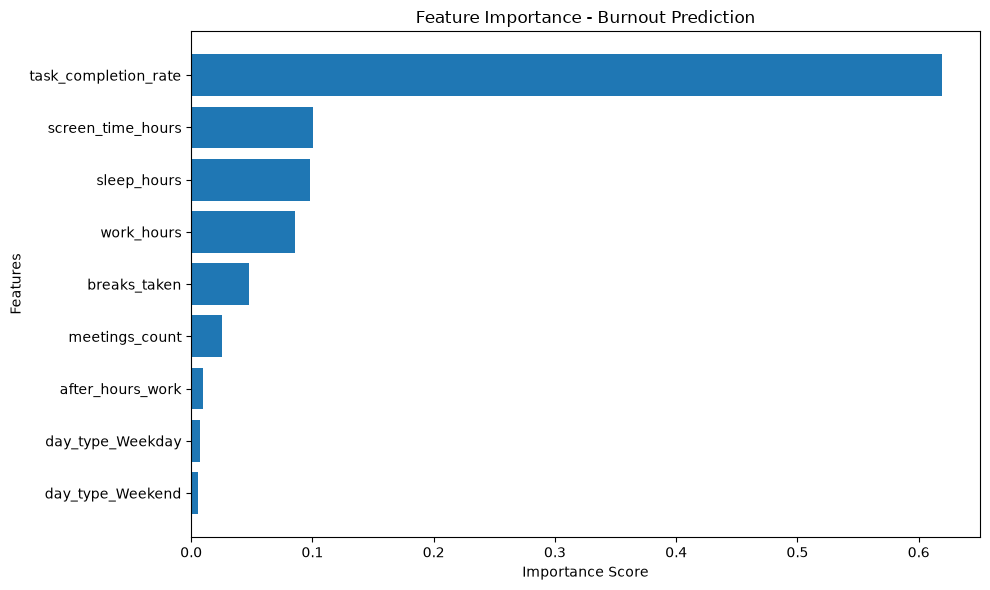

In [40]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = pd.DataFrame({
    "Feature": X_train_resampled.columns,
    "Importance": model_v4.feature_importances_
})

# Sort from highest to lowest
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance - Burnout Prediction")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
